# IEEE-CIS Fraud Detection: feature engineering

Проверим несколько групп новых признаков на двух временных фолдах. Параметры XGBoost не меняются, final holdout не используется.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 200)

RANDOM_STATE = 42
TARGET = "isFraud"
ID_COLUMN = "TransactionID"
SECONDS_PER_DAY = 86_400

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent
data_dir = project_root / "data"

## 1. Загрузка данных

Используем тот же набор признаков, что и в baseline.

In [2]:
transaction_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    *[f"C{i}" for i in range(1, 15)],
    *[f"D{i}" for i in range(1, 16)],
    *[f"M{i}" for i in range(1, 10)],
]

selected_v_columns = """
V281 V282 V283 V289 V296 V301 V314 V1 V3 V4 V6 V8 V11 V13 V14 V17 V20
V23 V26 V27 V30 V36 V37 V40 V41 V44 V47 V48 V54 V55 V56 V59 V62 V65 V67
V68 V70 V76 V78 V80 V82 V86 V88 V89 V91 V127 V98 V99 V107 V108 V109 V111
V114 V115 V117 V120 V121 V123 V129 V130 V131 V138 V139 V142 V147 V155 V162
V165 V160 V166 V203 V207 V173 V169 V171 V174 V175 V180 V185 V198 V210 V209
V264 V223 V240 V241 V260 V277 V220 V221 V234 V238 V250 V271 V307 V284 V285
V286 V291 V303 V305 V309 V310 V312 V320 V332 V325 V335
""".split()

model_transaction_columns = transaction_columns + selected_v_columns

categorical_columns = [
    "ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28",
    "id_29", "id_30", "id_31", "id_33", "id_34", "id_35",
    "id_36", "id_37", "id_38", "DeviceType", "DeviceInfo",
]
identity_columns = [
    *[f"id_{i:02d}" for i in range(1, 10)],
    *[f"id_{i}" for i in range(10, 39)],
]

dtypes = {column: "float32" for column in model_transaction_columns + identity_columns}
dtypes.update({column: "category" for column in categorical_columns})
dtypes[ID_COLUMN] = "int32"
dtypes[TARGET] = "int8"

In [3]:
transactions = pd.read_csv(
    data_dir / "train_transaction.csv",
    index_col=ID_COLUMN,
    usecols=model_transaction_columns + [TARGET],
    dtype=dtypes,
)
identity = pd.read_csv(
    data_dir / "train_identity.csv",
    index_col=ID_COLUMN,
    dtype=dtypes,
)

X = transactions.join(identity, how="left")
y = X.pop(TARGET)
del transactions, identity


print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Fraud rate: {y.mean():.2%}")
print(f"X memory: {memory_mb:.1f} MB")

X shape: (590540, 201)
y shape: (590540,)
Fraud rate: 3.50%
X memory: 404.6 MB


## 2. Схема экспериментов

Каждый новый набор сравниваем с предыдущим вариантом отдельно на каждом временном фолде.

In [4]:
relative_day = (X["TransactionDT"] // SECONDS_PER_DAY).astype("int16")

time_masks = {
    "dev_train": relative_day.between(1, 92),
    "dev_gap": relative_day.between(93, 122),
    "dev_validation": relative_day.between(123, 152),
    "final_holdout": relative_day.between(153, 182),
}

In [5]:
split_summary = pd.DataFrame(
    {
        "rows": int(mask.sum()),
        "first_day": int(relative_day.loc[mask].min()),
        "last_day": int(relative_day.loc[mask].max()),
        "fraud_rate": y.loc[mask].mean(),
    }
    for mask in time_masks.values()
)
split_summary.index = time_masks.keys()
split_summary["fraud_rate"] = split_summary["fraud_rate"].map("{:.2%}".format)
display(split_summary)

                  rows  first_day  last_day fraud_rate
dev_train       326186          1        92      3.38%
dev_gap          93880         93       122      4.00%
dev_validation   85044        123       152      3.39%
final_holdout    85430        153       182      3.50%


In [6]:
dev_train_mask = time_masks["dev_train"]
dev_valid_mask = time_masks["dev_validation"]
X_dev_train = X.loc[dev_train_mask]
y_dev_train = y.loc[dev_train_mask]
X_dev_valid = X.loc[dev_valid_mask]
y_dev_valid = y.loc[dev_valid_mask]

print("Development train:", X_dev_train.shape)
print("Development validation:", X_dev_valid.shape)

Development train: (326186, 201)
Development validation: (85044, 201)


In [7]:
def make_preprocessor(data):
    cat_columns = [
        column for column in categorical_columns
        if column in data.columns
    ]
    numeric_columns = [
        column for column in data.columns
        if column not in cat_columns
    ]

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                    encoded_missing_value=-2,
                    dtype=np.float32,
                ),
                cat_columns,
            ),
            ("numeric", "passthrough", numeric_columns),
        ],
        verbose_feature_names_out=False,
    )


preprocessor = make_preprocessor(X_dev_train)

In [8]:
def calculate_metrics(model_name, y_train, train_proba, y_valid, valid_proba, fit_seconds):
    train_roc_auc = roc_auc_score(y_train, train_proba)
    valid_roc_auc = roc_auc_score(y_valid, valid_proba)

    return {
        "model": model_name,
        "train_roc_auc": train_roc_auc,
        "valid_roc_auc": valid_roc_auc,
        "roc_auc_gap": train_roc_auc - valid_roc_auc,
        "train_pr_auc": average_precision_score(y_train, train_proba),
        "valid_pr_auc": average_precision_score(y_valid, valid_proba),
        "fit_seconds": fit_seconds,
    }


def run_experiment(
    train_data,
    y_train,
    valid_data,
    y_valid,
    model,
    experiment,
    fold,
    preprocessor=None,
):
    started = perf_counter()

    if preprocessor is None:
        train_matrix = train_data
        valid_matrix = valid_data
    else:
        encoder = clone(preprocessor)
        train_matrix = encoder.fit_transform(train_data)
        valid_matrix = encoder.transform(valid_data)

    fitted_model = clone(model)
    fitted_model.fit(
        train_matrix,
        y_train,
        eval_set=[(valid_matrix, y_valid)],
        verbose=False,
    )

    train_proba = fitted_model.predict_proba(train_matrix)[:, 1]
    valid_proba = fitted_model.predict_proba(valid_matrix)[:, 1]

    result = calculate_metrics(
        "XGBoost",
        y_train,
        train_proba,
        y_valid,
        valid_proba,
        perf_counter() - started,
    )
    result["experiment"] = experiment
    result["fold"] = fold
    result["best_iteration"] = fitted_model.best_iteration

    print(f"{fold}: best iteration {fitted_model.best_iteration}")
    return result



result_columns = [
    "experiment", "fold", "train_roc_auc", "valid_roc_auc",
    "delta_valid_roc_auc", "roc_auc_gap", "valid_pr_auc",
    "delta_valid_pr_auc", "best_iteration", "fit_seconds",
]


def compare_with_reference(results, reference_name):
    table = pd.DataFrame(results)
    reference = table.query("experiment == @reference_name").set_index("fold")

    table["delta_valid_roc_auc"] = (
        table["valid_roc_auc"]
        - table["fold"].map(reference["valid_roc_auc"])
    )
    table["delta_valid_pr_auc"] = (
        table["valid_pr_auc"]
        - table["fold"].map(reference["valid_pr_auc"])
    )

    return table


def summarize_experiments(results, include_fit_time=True):
    summary = results.groupby("experiment", as_index=False).agg(
        mean_valid_roc_auc=("valid_roc_auc", "mean"),
        min_valid_roc_auc=("valid_roc_auc", "min"),
        mean_delta_roc_auc=("delta_valid_roc_auc", "mean"),
        mean_delta_pr_auc=("delta_valid_pr_auc", "mean"),
        mean_roc_auc_gap=("roc_auc_gap", "mean"),
    )

    if include_fit_time:
        mean_time = results.groupby("experiment")["fit_seconds"].mean()
        summary["mean_fit_seconds"] = summary["experiment"].map(mean_time)

    return summary.sort_values("mean_valid_roc_auc", ascending=False)

experiment_results = []

## 3. Baseline на двух фолдах

Сначала повторим baseline XGBoost, чтобы получить точку сравнения.

In [9]:
xgb_clf = XGBClassifier(
    n_estimators=2000,
    max_depth=4,
    learning_rate=0.01,
    eval_metric="auc",
    tree_method="hist",
    early_stopping_rounds=50,
    verbosity=0,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

fold2_result = run_experiment(
    X_dev_train,
    y_dev_train,
    X_dev_valid,
    y_dev_valid,
    xgb_clf,
    "baseline",
    "fold_2",
    preprocessor,
)
experiment_results.append(fold2_result)

Best iteration: 1999


In [10]:
fold1_masks = {
    "train": relative_day.between(1, 62),
    "gap": relative_day.between(63, 92),
    "validation": relative_day.between(93, 122),
}

fold1_summary = pd.DataFrame(
    {
        "rows": int(mask.sum()),
        "first_day": int(relative_day.loc[mask].min()),
        "last_day": int(relative_day.loc[mask].max()),
        "fraud_rate": y.loc[mask].mean(),
    }
    for mask in fold1_masks.values()
)

fold1_summary.index = fold1_masks.keys()
fold1_summary["fraud_rate"] = fold1_summary["fraud_rate"].map("{:.2%}".format)
display(fold1_summary)

X_fold1_train = X.loc[fold1_masks["train"]]
y_fold1_train = y.loc[fold1_masks["train"]]
X_fold1_valid = X.loc[fold1_masks["validation"]]
y_fold1_valid = y.loc[fold1_masks["validation"]]


print("Fold 1 train:", X_fold1_train.shape)
print("Fold 1 validation:", X_fold1_valid.shape)

              rows  first_day  last_day fraud_rate
train       229906          1        62      3.16%
gap          96280         63        92      3.92%
validation   93880         93       122      4.00%
Fold 1 train: (229906, 201)
Fold 1 validation: (93880, 201)


In [11]:
fold1_result = run_experiment(
    X_fold1_train,
    y_fold1_train,
    X_fold1_valid,
    y_fold1_valid,
    xgb_clf,
    "baseline",
    "fold_1",
    preprocessor,
)

Fold 1 best iteration: 1270


In [12]:
xgb_fold_table = pd.DataFrame([fold1_result, fold2_result])[
    [
        "experiment", "fold", "train_roc_auc", "valid_roc_auc",
        "roc_auc_gap", "train_pr_auc", "valid_pr_auc",
        "best_iteration", "fit_seconds",
    ]
]

display(xgb_fold_table.round(4))

  experiment    fold  train_roc_auc  valid_roc_auc  roc_auc_gap  train_pr_auc  valid_pr_auc  best_iteration  fit_seconds
0   baseline  fold_1         0.9246         0.8813       0.0434        0.6580        0.5229            1270      96.0794
1   baseline  fold_2         0.9297         0.8815       0.0482        0.6826        0.4813            1999     146.1201


## 4. Временные признаки

Добавим час, день недели и их циклическое представление.

In [13]:
def add_time_features(data):
    df = data.copy()

    df["hour"] = (df["TransactionDT"] // 3_600) % 24
    df["weekday"] = (df["TransactionDT"] // SECONDS_PER_DAY) % 7
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)

    return df

In [14]:
X_fold1_train_time = add_time_features(X_fold1_train)
X_fold1_valid_time = add_time_features(X_fold1_valid)
X_fold2_train_time = add_time_features(X_dev_train)
X_fold2_valid_time = add_time_features(X_dev_valid)

In [15]:
preprocessor_tf_v1 = make_preprocessor(X_fold1_train_time)

In [16]:
fold1_tf_v1_result = run_experiment(
    X_fold1_train_time,
    y_fold1_train,
    X_fold1_valid_time,
    y_fold1_valid,
    xgb_clf,
    "time_features_v1",
    "fold_1",
    preprocessor_tf_v1,
)

Fold 1 best iteration: 1406


In [17]:
fold2_tf_v1_result = run_experiment(
    X_fold2_train_time,
    y_dev_train,
    X_fold2_valid_time,
    y_dev_valid,
    xgb_clf,
    "time_features_v1",
    "fold_2",
    preprocessor_tf_v1,
)

Fold 2 best iteration: 1999


In [18]:
xgb_feature_results = compare_with_reference(
    [
        fold1_result,
fold2_result,
fold1_tf_v1_result,
fold2_tf_v1_result,
    ],
    "baseline",
)

display(
    xgb_feature_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

         experiment    fold  train_roc_auc  valid_roc_auc  delta_valid_roc_auc  roc_auc_gap  valid_pr_auc  delta_valid_pr_auc  best_iteration  fit_seconds
0          baseline  fold_1         0.9246         0.8813               0.0000       0.0434        0.5229              0.0000            1270      96.0794
2  time_features_v1  fold_1         0.9274         0.8818               0.0006       0.0455        0.5235              0.0005            1406     107.8175
1          baseline  fold_2         0.9297         0.8815               0.0000       0.0482        0.4813              0.0000            1999     146.1201
3  time_features_v1  fold_2         0.9298         0.8823               0.0008       0.0475        0.4868              0.0055            1999     156.7021


In [19]:
experiment_summary = summarize_experiments(
    xgb_feature_results,
    include_fit_time=True,
)
display(experiment_summary.round(4))

         experiment  mean_valid_roc_auc  min_valid_roc_auc  mean_delta_roc_auc  mean_delta_pr_auc  mean_roc_auc_gap  mean_fit_seconds
1  time_features_v1              0.8821             0.8818              0.0007              0.003            0.0465          132.2598
0          baseline              0.8814             0.8813              0.0000              0.000            0.0458          121.0997


### Вывод

Временные признаки улучшили ROC-AUC на обоих фолдах: среднее выросло с 0.8814 до 0.8821. Оставляем эту группу.

## 5. Признаки суммы

Проверим логарифм суммы, дробную часть и флаг целого значения.

In [20]:
def add_amount_features(data):
    df = data.copy()

    amount = df['TransactionAmt']
    df['TransactionAmt_log1p'] = np.log1p(amount)
    df['TransactionAmt_fraction'] = (amount - np.floor(amount)).round(3)
    df['TransactionAmt_is_integer'] = (
        df['TransactionAmt_fraction'] == 0
    ).astype('int8')

    return df

In [21]:
X_fold1_train_time_amount = add_amount_features(X_fold1_train_time)
X_fold1_valid_time_amount = add_amount_features(X_fold1_valid_time)
X_fold2_train_time_amount = add_amount_features(X_fold2_train_time)
X_fold2_valid_time_amount = add_amount_features(X_fold2_valid_time)

In [22]:
preprocessor_time_amount_v1 = make_preprocessor(X_fold1_train_time_amount)

In [23]:
fold1_time_amount_v1_result = run_experiment(
    X_fold1_train_time_amount,
    y_fold1_train,
    X_fold1_valid_time_amount,
    y_fold1_valid,
    xgb_clf,
    "time_amount_features_v1",
    "fold_1",
    preprocessor_time_amount_v1,
)

Fold 1 best iteration: 1280


In [24]:
fold2_time_amount_v1_result = run_experiment(
    X_fold2_train_time_amount,
    y_dev_train,
    X_fold2_valid_time_amount,
    y_dev_valid,
    xgb_clf,
    "time_amount_features_v1",
    "fold_2",
    preprocessor_time_amount_v1,
)

Fold 2 best iteration: 1992


In [25]:
amount_feature_results = compare_with_reference(
    [
        fold1_tf_v1_result,
fold2_tf_v1_result,
fold1_time_amount_v1_result,
fold2_time_amount_v1_result,
    ],
    "time_features_v1",
)

display(
    amount_feature_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

                experiment    fold  train_roc_auc  valid_roc_auc  delta_valid_roc_auc  roc_auc_gap  valid_pr_auc  delta_valid_pr_auc  best_iteration  fit_seconds
2  time_amount_features_v1  fold_1         0.9253         0.8815              -0.0003       0.0438        0.5226             -0.0008            1280     107.9877
0         time_features_v1  fold_1         0.9274         0.8818               0.0000       0.0455        0.5235              0.0000            1406     107.8175
3  time_amount_features_v1  fold_2         0.9298         0.8821              -0.0002       0.0477        0.4868             -0.0000            1992     164.4597
1         time_features_v1  fold_2         0.9298         0.8823               0.0000       0.0475        0.4868              0.0000            1999     156.7021


In [26]:
amount_experiment_summary = summarize_experiments(
    amount_feature_results,
    include_fit_time=False,
)
display(amount_experiment_summary.round(4))

                experiment  mean_valid_roc_auc  min_valid_roc_auc  mean_delta_roc_auc  mean_delta_pr_auc  mean_roc_auc_gap
1         time_features_v1              0.8821             0.8818              0.0000             0.0000            0.0465
0  time_amount_features_v1              0.8818             0.8815             -0.0002            -0.0004            0.0457


### Вывод

Новые признаки суммы немного ухудшили оба фолда. XGBoost достаточно исходного `TransactionAmt`, поэтому группу не используем.

## 6. Категории внутри XGBoost

Сравним `OrdinalEncoder` со встроенной обработкой категорий XGBoost.

In [27]:
xgb_native_v1 = clone(xgb_clf).set_params(enable_categorical=True)

In [28]:
fold1_native_v1_result = run_experiment(
    X_fold1_train_time,
    y_fold1_train,
    X_fold1_valid_time,
    y_fold1_valid,
    xgb_native_v1,
    "native_categorical_v1",
    "fold_1",
)

Fold 1 best iteration: 1252


In [29]:
fold2_native_v1_result = run_experiment(
    X_fold2_train_time,
    y_dev_train,
    X_fold2_valid_time,
    y_dev_valid,
    xgb_native_v1,
    "native_categorical_v1",
    "fold_2",
)

Fold 2 best iteration: 1997


In [30]:
native_categorical_results = compare_with_reference(
    [
        fold1_tf_v1_result,
fold2_tf_v1_result,
fold1_native_v1_result,
fold2_native_v1_result,
    ],
    "time_features_v1",
)

display(
    native_categorical_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

              experiment    fold  train_roc_auc  valid_roc_auc  delta_valid_roc_auc  roc_auc_gap  valid_pr_auc  delta_valid_pr_auc  best_iteration  fit_seconds
2  native_categorical_v1  fold_1         0.9337         0.8745              -0.0073       0.0592        0.4417             -0.0817            1252     111.8303
0       time_features_v1  fold_1         0.9274         0.8818               0.0000       0.0455        0.5235              0.0000            1406     115.8015
3  native_categorical_v1  fold_2         0.9364         0.8700              -0.0123       0.0665        0.3494             -0.1374            1997     169.9411
1       time_features_v1  fold_2         0.9298         0.8823               0.0000       0.0475        0.4868              0.0000            1999     157.5914


In [31]:
native_experiment_summary = summarize_experiments(
    native_categorical_results,
    include_fit_time=True,
)
display(native_experiment_summary.round(4))

              experiment  mean_valid_roc_auc  min_valid_roc_auc  mean_delta_roc_auc  mean_delta_pr_auc  mean_roc_auc_gap  mean_fit_seconds
1       time_features_v1              0.8821             0.8818              0.0000             0.0000            0.0465          136.6965
0  native_categorical_v1              0.8722             0.8700             -0.0098            -0.1095            0.0628          140.8857


### Вывод

Native categorical снизил средний ROC-AUC примерно на 0.0098 и сильнее переобучился. Оставляем `OrdinalEncoder`.

## 7. Признаки пропусков

Добавим число пропусков по нескольким группам и флаг `has_identity`.

In [32]:
base_feature_columns = X.columns.tolist()
transaction_feature_columns = [
    column for column in model_transaction_columns
    if column in X.columns
]
identity_feature_columns = [
    column for column in identity_columns
    if column in X.columns
]
v_feature_columns = [
    column for column in selected_v_columns
    if column in X.columns
]

def add_missing_features(data):
    df = data.copy()

    df['missing_count_total'] = (
        df[base_feature_columns].isna().sum(axis=1).astype('int16')
    )
    df['missing_count_transaction'] = (
        df[transaction_feature_columns].isna().sum(axis=1).astype('int16')
    )
    df['missing_count_identity'] = (
        df[identity_feature_columns].isna().sum(axis=1).astype('int8')
    )
    df['missing_count_v'] = (
        df[v_feature_columns].isna().sum(axis=1).astype('int16')
    )
    df['has_identity'] = (
        df[identity_feature_columns].notna().any(axis=1).astype('int8')
    )

    return df

In [33]:
X_fold1_train_time_missing = add_missing_features(X_fold1_train_time)
X_fold1_valid_time_missing = add_missing_features(X_fold1_valid_time)
X_fold2_train_time_missing = add_missing_features(X_fold2_train_time)
X_fold2_valid_time_missing = add_missing_features(X_fold2_valid_time)

In [34]:
preprocessor_time_missing_v1 = make_preprocessor(X_fold1_train_time_missing)

In [35]:
fold1_time_missing_v1_result = run_experiment(
    X_fold1_train_time_missing,
    y_fold1_train,
    X_fold1_valid_time_missing,
    y_fold1_valid,
    xgb_clf,
    "time_missing_features_v1",
    "fold_1",
    preprocessor_time_missing_v1,
)

Fold 1 best iteration: 1318


In [36]:
fold2_time_missing_v1_result = run_experiment(
    X_fold2_train_time_missing,
    y_dev_train,
    X_fold2_valid_time_missing,
    y_dev_valid,
    xgb_clf,
    "time_missing_features_v1",
    "fold_2",
    preprocessor_time_missing_v1,
)

Fold 2 best iteration: 1999


In [37]:
missing_feature_results = compare_with_reference(
    [
        fold1_tf_v1_result,
fold2_tf_v1_result,
fold1_time_missing_v1_result,
fold2_time_missing_v1_result,
    ],
    "time_features_v1",
)

display(
    missing_feature_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

                 experiment    fold  train_roc_auc  valid_roc_auc  delta_valid_roc_auc  roc_auc_gap  valid_pr_auc  delta_valid_pr_auc  best_iteration  fit_seconds
0          time_features_v1  fold_1         0.9274         0.8818               0.0000       0.0455        0.5235              0.0000            1406     113.7510
2  time_missing_features_v1  fold_1         0.9258         0.8809              -0.0009       0.0449        0.5204             -0.0031            1318     114.9811
1          time_features_v1  fold_2         0.9298         0.8823               0.0000       0.0475        0.4868              0.0000            1999     151.4947
3  time_missing_features_v1  fold_2         0.9298         0.8820              -0.0003       0.0478        0.4850             -0.0018            1999     163.0553


In [38]:
missing_experiment_summary = summarize_experiments(
    missing_feature_results,
    include_fit_time=True,
)
display(missing_experiment_summary.round(4))

                 experiment  mean_valid_roc_auc  min_valid_roc_auc  mean_delta_roc_auc  mean_delta_pr_auc  mean_roc_auc_gap  mean_fit_seconds
0          time_features_v1              0.8821             0.8818              0.0000             0.0000            0.0465          132.6228
1  time_missing_features_v1              0.8814             0.8809             -0.0006            -0.0024            0.0463          139.0182


### Вывод

Счётчики пропусков снизили средний ROC-AUC на 0.0006. XGBoost уже использует исходные пропуски, поэтому группу не оставляем.

## 8. Frequency encoding

Для card-, address-, email- и device-признаков добавим частоту значения. Частоты считаются только на train каждого фолда.

In [39]:
frequency_columns = [
    "card1", "card2", "card3", "card5",
    "addr1", "addr2",
    "P_emaildomain", "R_emaildomain",
    "DeviceInfo", "id_31",
]

def add_frequency_features(train_data, valid_data, columns):
    train_df = train_data.copy()
    valid_df = valid_data.copy()

    for column in columns:
        train_values = train_df[column].astype("string").fillna("__MISSING__")
        valid_values = valid_df[column].astype("string").fillna("__MISSING__")

        frequency_map = train_values.value_counts(normalize=True)
        feature_name = f"{column}_freq"

        train_df[feature_name] = (
            train_values.map(frequency_map).astype("float32")
        )
        valid_df[feature_name] = (
            valid_values.map(frequency_map).fillna(0).astype("float32")
        )

    return train_df, valid_df

In [40]:
X_fold1_train_frequency, X_fold1_valid_frequency = add_frequency_features(
    X_fold1_train_time,
    X_fold1_valid_time,
    frequency_columns,
)

X_fold2_train_frequency, X_fold2_valid_frequency = add_frequency_features(
    X_fold2_train_time,
    X_fold2_valid_time,
    frequency_columns,
)

In [41]:
preprocessor_frequency_v1 = make_preprocessor(X_fold1_train_frequency)

In [42]:
fold1_frequency_v1_result = run_experiment(
    X_fold1_train_frequency,
    y_fold1_train,
    X_fold1_valid_frequency,
    y_fold1_valid,
    xgb_clf,
    "frequency_encoding_v1",
    "fold_1",
    preprocessor_frequency_v1,
)

Fold 1 best iteration: 1721


In [43]:
fold2_frequency_v1_result = run_experiment(
    X_fold2_train_frequency,
    y_dev_train,
    X_fold2_valid_frequency,
    y_dev_valid,
    xgb_clf,
    "frequency_encoding_v1",
    "fold_2",
    preprocessor_frequency_v1,
)

Fold 2 best iteration: 1999


In [44]:
frequency_feature_results = compare_with_reference(
    [
        fold1_tf_v1_result,
fold2_tf_v1_result,
fold1_frequency_v1_result,
fold2_frequency_v1_result,
    ],
    "time_features_v1",
)

display(
    frequency_feature_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

              experiment    fold  train_roc_auc  valid_roc_auc  delta_valid_roc_auc  roc_auc_gap  valid_pr_auc  delta_valid_pr_auc  best_iteration  fit_seconds
2  frequency_encoding_v1  fold_1         0.9337         0.8851               0.0033       0.0486        0.5275              0.0041            1721     144.2037
0       time_features_v1  fold_1         0.9274         0.8818               0.0000       0.0455        0.5235              0.0000            1406     113.1098
3  frequency_encoding_v1  fold_2         0.9327         0.8804              -0.0019       0.0523        0.4713             -0.0155            1999     159.1861
1       time_features_v1  fold_2         0.9298         0.8823               0.0000       0.0475        0.4868              0.0000            1999     152.2201


In [45]:
frequency_experiment_summary = summarize_experiments(
    frequency_feature_results,
    include_fit_time=True,
)
display(frequency_experiment_summary.round(4))

              experiment  mean_valid_roc_auc  min_valid_roc_auc  mean_delta_roc_auc  mean_delta_pr_auc  mean_roc_auc_gap  mean_fit_seconds
0  frequency_encoding_v1              0.8828             0.8804              0.0007            -0.0057            0.0504          151.6949
1       time_features_v1              0.8821             0.8818              0.0000             0.0000            0.0465          132.6649


### Вывод

Frequency encoding помог на первом фолде, но ухудшил второй. Из-за нестабильности во времени группу не используем.

## 9. Нормализация D-признаков

`D1–D15` связаны со временем. Проверим преобразование:

```text
normalized_D = D - transaction_day
```

Признак выбираем, если после преобразования он становится стабильнее для повторных транзакций одного proxy-клиента. Для proxy используем `card1`, `addr1` и нормализованный `D1`.

In [46]:
import matplotlib.pyplot as plt

d_columns = [f"D{i}" for i in range(1, 16)]

d_analysis = X_dev_train[
    ["TransactionDT", "card1", "addr1", *d_columns]
].copy()

d_analysis["transaction_day"] = (
    d_analysis["TransactionDT"] / SECONDS_PER_DAY
)

d_analysis["uid_proxy"] = (
    d_analysis["card1"].astype("string")
    + "_"
    + d_analysis["addr1"].astype("string")
    + "_"
    + np.floor(
        d_analysis["transaction_day"] - d_analysis["D1"]
    ).astype("string")
)

d_diagnostic_rows = []

for column in d_columns:
    sequence = (
        d_analysis[["uid_proxy", "transaction_day", column]]
        .dropna()
        .sort_values(["uid_proxy", "transaction_day"])
    )

    group_size = sequence.groupby("uid_proxy")[column].transform("size")
    sequence = sequence.loc[group_size >= 2].copy()

    sequence["day_delta"] = (
        sequence.groupby("uid_proxy")["transaction_day"].diff()
    )
    sequence["raw_delta"] = (
        sequence.groupby("uid_proxy")[column].diff()
    )
    sequence = sequence.loc[sequence["day_delta"] > 0]
    sequence["normalized_delta"] = (
        sequence["raw_delta"] - sequence["day_delta"]
    )

    raw_step = sequence["raw_delta"].abs()
    normalized_step = sequence["normalized_delta"].abs()

    d_diagnostic_rows.append({
        "feature": column,
        "missing_rate": d_analysis[column].isna().mean(),
        "median_abs_raw_step": raw_step.median(),
        "median_abs_normalized_step": normalized_step.median(),
        "normalized_step_better_rate": (normalized_step < raw_step).mean(),
    })

d_diagnostics = pd.DataFrame(d_diagnostic_rows).set_index("feature")

d_diagnostics["selected"] = (
    (d_diagnostics["missing_rate"] < 0.80)
    & (
        d_diagnostics["median_abs_normalized_step"]
        < d_diagnostics["median_abs_raw_step"]
    )
    & (d_diagnostics["normalized_step_better_rate"] > 0.50)
)

selected_d_columns = d_diagnostics.index[
    d_diagnostics["selected"]
].tolist()

display(d_diagnostics.round(4))
print("Selected D columns:", selected_d_columns)

Selected D columns: ['D1', 'D2', 'D4', 'D10', 'D11', 'D15']


,missing_rate,median_abs_raw_step,median_abs_normalized_step,normalized_step_better_rate,selected
feature,,,,,
D1,0.0000,2.0000,0.1060,0.5748,True
D2,0.5091,6.0000,0.1298,0.7730,True
D3,0.4843,5.0000,7.0004,0.2611,False
D4,0.3201,6.0000,0.1666,0.6182,True
D5,0.5583,7.0000,9.1648,0.2594,False
D6,0.8722,0.0000,0.0530,0.3937,False
D7,0.9357,1.0000,1.3360,0.1823,False
D8,0.8546,0.1667,0.0112,0.3984,False
D9,0.8546,0.0417,0.0070,0.3298,False


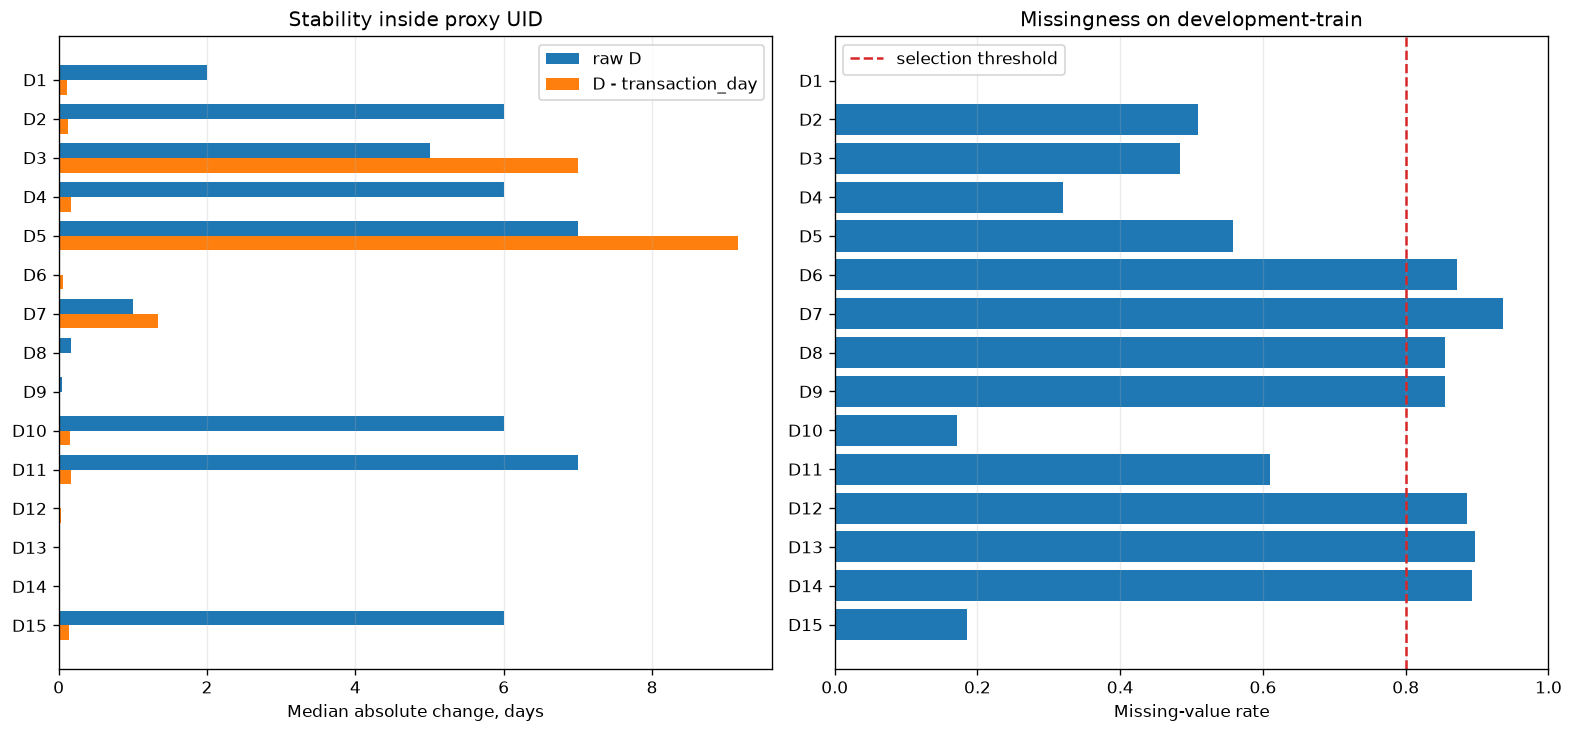

In [47]:
positions = np.arange(len(d_diagnostics))
bar_height = 0.38

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)

axes[0].barh(
    positions - bar_height / 2,
    d_diagnostics["median_abs_raw_step"],
    height=bar_height,
    label="raw D",
)
axes[0].barh(
    positions + bar_height / 2,
    d_diagnostics["median_abs_normalized_step"],
    height=bar_height,
    label="D - transaction_day",
)
axes[0].set(
    yticks=positions,
    yticklabels=d_diagnostics.index,
    xlabel="Median absolute change, days",
    title="Stability inside proxy UID",
)
axes[0].legend()

axes[1].barh(positions, d_diagnostics["missing_rate"])
axes[1].axvline(0.80, color="tab:red", linestyle="--", label="selection threshold")
axes[1].set(
    yticks=positions,
    yticklabels=d_diagnostics.index,
    xlabel="Missing-value rate",
    title="Missingness on development-train",
    xlim=(0, 1),
)
axes[1].legend()

for axis in axes:
    axis.invert_yaxis()
    axis.grid(axis="x", alpha=0.25)

plt.show()

### Выбор D-признаков

Оставляем признаки с долей пропусков ниже 80%, меньшим медианным шагом после нормализации и улучшением более чем в половине пар. Получились `D1`, `D2`, `D4`, `D10`, `D11`, `D15`.

In [ ]:
def normalize_selected_d_features(data, columns=selected_d_columns):
    df = data.copy()
    transaction_day = df["TransactionDT"] / SECONDS_PER_DAY

    for column in columns:
        df[column] = (df[column] - transaction_day).astype("float32")

    return df

In [49]:
X_fold1_train_d_norm = normalize_selected_d_features(X_fold1_train_time)
X_fold1_valid_d_norm = normalize_selected_d_features(X_fold1_valid_time)
X_fold2_train_d_norm = normalize_selected_d_features(X_fold2_train_time)
X_fold2_valid_d_norm = normalize_selected_d_features(X_fold2_valid_time)

In [50]:
preprocessor_d_norm_v1 = make_preprocessor(X_fold1_train_d_norm)

In [51]:
fold1_d_norm_v1_result = run_experiment(
    X_fold1_train_d_norm,
    y_fold1_train,
    X_fold1_valid_d_norm,
    y_fold1_valid,
    xgb_clf,
    "d_normalization_selected_v1",
    "fold_1",
    preprocessor_d_norm_v1,
)

Fold 1 best iteration: 1999


In [52]:
fold2_d_norm_v1_result = run_experiment(
    X_fold2_train_d_norm,
    y_dev_train,
    X_fold2_valid_d_norm,
    y_dev_valid,
    xgb_clf,
    "d_normalization_selected_v1",
    "fold_2",
    preprocessor_d_norm_v1,
)

Fold 2 best iteration: 1999


In [53]:
d_normalization_results = compare_with_reference(
    [
        fold1_tf_v1_result,
fold2_tf_v1_result,
fold1_d_norm_v1_result,
fold2_d_norm_v1_result,
    ],
    "time_features_v1",
)

display(
    d_normalization_results[result_columns]
    .sort_values(["fold", "experiment"])
    .round(4)
)

,experiment,fold,train_roc_auc,valid_roc_auc,delta_valid_roc_auc,roc_auc_gap,valid_pr_auc,delta_valid_pr_auc,best_iteration,fit_seconds
2,d_normalization_selected_v1,fold_1,0.9372,0.8845,0.0026,0.0528,0.5266,0.0032,1999,151.4659
0,time_features_v1,fold_1,0.9274,0.8818,0.0000,0.0455,0.5235,0.0000,1406,113.0052
3,d_normalization_selected_v1,fold_2,0.9320,0.8826,0.0003,0.0494,0.4914,0.0046,1999,156.1563
1,time_features_v1,fold_2,0.9298,0.8823,0.0000,0.0475,0.4868,0.0000,1999,151.3534


In [54]:
d_normalization_summary = summarize_experiments(
    d_normalization_results,
    include_fit_time=True,
)
display(d_normalization_summary.round(4))

,experiment,mean_valid_roc_auc,min_valid_roc_auc,mean_delta_roc_auc,mean_delta_pr_auc,mean_roc_auc_gap,mean_fit_seconds
0,d_normalization_selected_v1,0.8835,0.8826,0.0015,0.0039,0.0511,153.8111
1,time_features_v1,0.8821,0.8818,0.0000,0.0000,0.0465,132.1793


### Вывод

Нормализация выбранных `D` улучшила оба фолда. Средний ROC-AUC вырос с 0.8821 до 0.8835, PR-AUC — на 0.0039. Этот набор используем дальше.